# Analyse de l'inflation trimestrielle avec SQL

Fichier : `Inflation_-_Tableau_1.xlsx` (inflation en variation annuelle, en %, de 2013 T1 à 2026 T2).

Démarche : on charge le fichier dans une base SQLite, puis chaque graphique est précédé d'une **requête SQL** dont le résultat sert à le tracer.

Avant de lancer : dépose le fichier dans ton Drive (dossier *Mon Drive*) ou glisse-le dans le panneau de fichiers de Colab.

## 1. Accès au fichier

In [1]:
# Option A : via Google Drive
from google.colab import drive
drive.mount('/content/drive')
CHEMIN = "/content/drive/MyDrive/inflationnn /Inflation - Tableau.xlsxs"

Mounted at /content/drive


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Lecture et nettoyage

Dans le fichier, l'année n'est écrite que sur la ligne T1 (les lignes T2, T3, T4 n'ont que le trimestre), et les deux derniers trimestres sont vides. On reconstruit donc une colonne `annee` complète avant de passer en SQL. Les noms de colonnes sont écrits sans accents ni espaces pour simplifier le SQL.

In [3]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# Lecture brute : on garde les deux dernières colonnes (période, inflation)
brut = pd.read_excel(CHEMIN, header=None).iloc[:, -2:]
brut.columns = ["periode_brute", "inflation"]
brut["periode_brute"] = brut["periode_brute"].astype(str).str.strip()

# Reconstruction de l'année (propagée vers le bas) et du trimestre
brut["annee"] = brut["periode_brute"].str.extract(r"(\d{4})")[0].ffill()
brut["trimestre"] = brut["periode_brute"].str.extract(r"(T\d)")[0]

# On enlève la ligne d'en-tête et les trimestres sans valeur
df = brut.dropna(subset=["trimestre", "annee"]).copy()
df["inflation"] = pd.to_numeric(df["inflation"], errors="coerce")
df = df.dropna(subset=["inflation"]).reset_index(drop=True)

df["annee"] = df["annee"].astype(int)
df["periode"] = df["annee"].astype(str) + " " + df["trimestre"]
df["ordre"] = range(1, len(df) + 1)          # numéro chronologique

df = df[["ordre", "periode", "annee", "trimestre", "inflation"]]
print(df.shape)
df.head()

(54, 5)


,ordre,periode,annee,trimestre,inflation
0,1,2013 T1,2013,T1,2.304577
1,2,2013 T2,2013,T2,2.485969
2,3,2013 T3,2013,T3,1.736803
3,4,2013 T4,2013,T4,0.981906
4,5,2014 T1,2014,T1,0.444498


## 3. Création de la base SQLite

In [4]:
conn = sqlite3.connect("inflation.db")     # base temporaire (disparaît à la fermeture de Colab)
df.to_sql("inflation", conn, if_exists="replace", index=False)

def sql(requete):
    """Exécute une requête SQL et renvoie le résultat sous forme de tableau."""
    return pd.read_sql(requete, conn)

sql("SELECT name, sql FROM sqlite_master WHERE type='table'")

,name,sql
0,inflation,"CREATE TABLE ""inflation"" (\n""ordre"" INTEGER,\n..."


## 4. Requête 1 : aperçu des données

Affiche les premières lignes de la table pour vérifier que le chargement est correct.

In [5]:
sql("""
SELECT *
FROM inflation
LIMIT 10;
""")

,ordre,periode,annee,trimestre,inflation
0,1,2013 T1,2013,T1,2.304577
1,2,2013 T2,2013,T2,2.485969
2,3,2013 T3,2013,T3,1.736803
3,4,2013 T4,2013,T4,0.981906
4,5,2014 T1,2014,T1,0.444498
5,6,2014 T2,2014,T2,0.030313
6,7,2014 T3,2014,T3,0.147861
7,8,2014 T4,2014,T4,1.149642
8,9,2015 T1,2015,T1,1.500000
9,10,2015 T2,2015,T2,2.000000


## 5. Requête 2 : statistiques globales

Nombre de trimestres, inflation moyenne, minimale et maximale sur toute la période.

In [6]:
sql("""
SELECT COUNT(*)                     AS nb_trimestres,
       ROUND(AVG(inflation), 2)     AS moyenne,
       ROUND(MIN(inflation), 2)     AS minimum,
       ROUND(MAX(inflation), 2)     AS maximum
FROM inflation;
""")

,nb_trimestres,moyenne,minimum,maximum
0,54,1.85,-0.2,9.1


## 6. Requête 3 + graphique 1 : évolution trimestrielle

On sélectionne toute la série dans l'ordre chronologique, avec un repère visuel à 2 % (cible habituelle des banques centrales).

,ordre,periode,inflation
0,1,2013 T1,2.304577
1,2,2013 T2,2.485969
2,3,2013 T3,1.736803
3,4,2013 T4,0.981906
4,5,2014 T1,0.444498


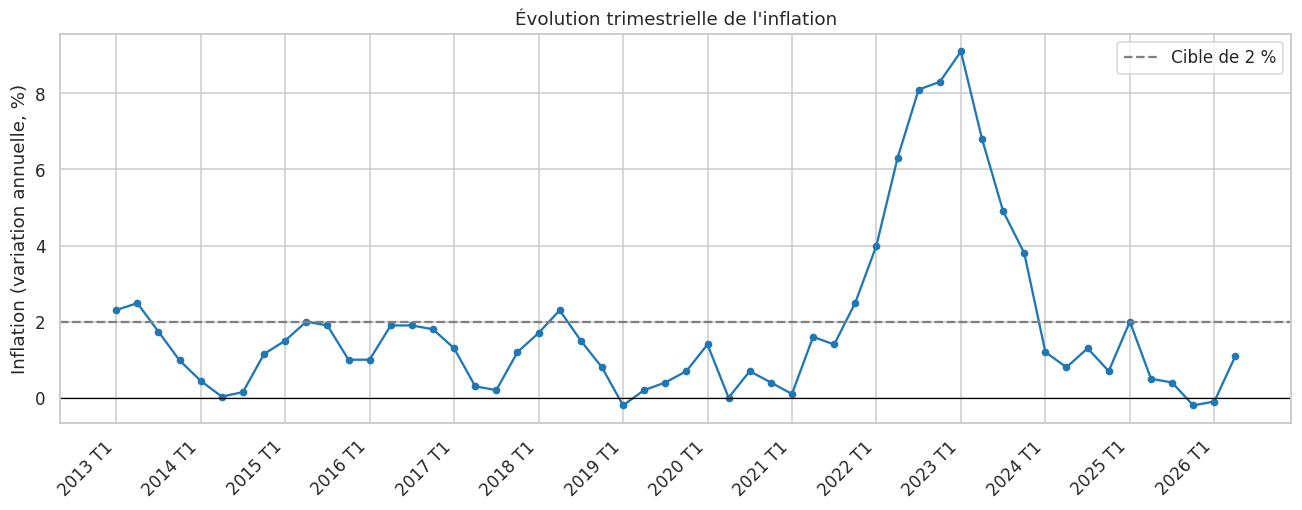

In [7]:
q3 = sql("""
SELECT ordre, periode, inflation
FROM inflation
ORDER BY ordre;
""")
display(q3.head())

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(q3["ordre"], q3["inflation"], marker="o", markersize=4, color="tab:blue")
ax.axhline(2, color="grey", linestyle="--", label="Cible de 2 %")
ax.axhline(0, color="black", linewidth=0.8)
pas = 4                                      # une étiquette par an
ax.set_xticks(q3["ordre"][::pas])
ax.set_xticklabels(q3["periode"][::pas], rotation=45, ha="right")
ax.set_ylabel("Inflation (variation annuelle, %)")
ax.set_title("Évolution trimestrielle de l'inflation")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Requête 4 + graphique 2 : inflation moyenne par année

`GROUP BY annee` regroupe les 4 trimestres de chaque année et calcule la moyenne. Les années incomplètes (2026) sont signalées par le nombre de trimestres.

,annee,inflation_moyenne,nb_trimestres
0,2013,1.88,4
1,2014,0.44,4
2,2015,1.60,4
3,2016,1.65,4
4,2017,0.75,4
5,2018,1.57,4
6,2019,0.28,4
7,2020,0.63,4
8,2021,1.40,4
9,2022,6.67,4


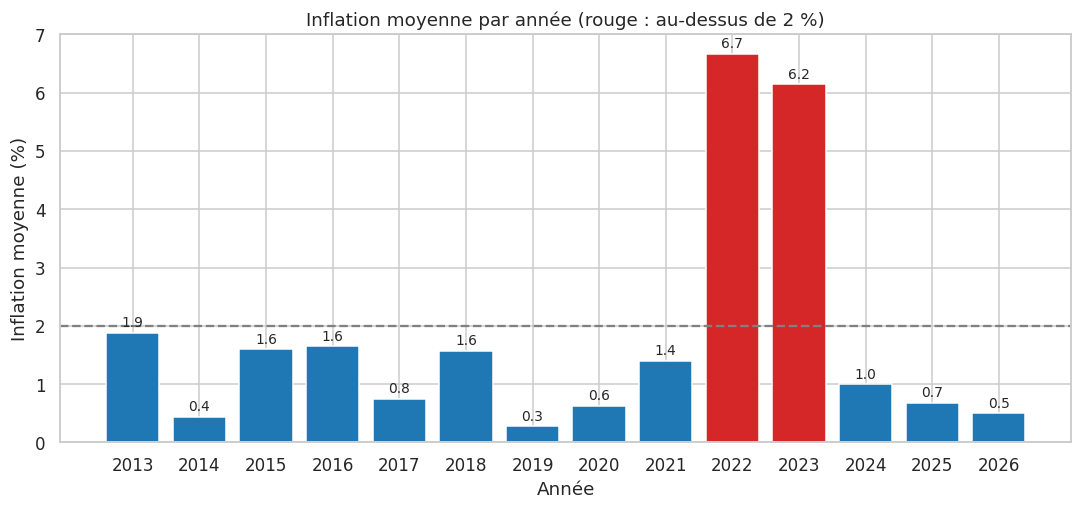

In [8]:
q4 = sql("""
SELECT annee,
       ROUND(AVG(inflation), 2) AS inflation_moyenne,
       COUNT(*)                 AS nb_trimestres
FROM inflation
GROUP BY annee
ORDER BY annee;
""")
display(q4)

fig, ax = plt.subplots(figsize=(10, 4.8))
couleurs = ["tab:red" if v > 2 else "tab:blue" for v in q4["inflation_moyenne"]]
ax.bar(q4["annee"].astype(str), q4["inflation_moyenne"], color=couleurs)
for i, v in enumerate(q4["inflation_moyenne"]):
    ax.text(i, v + (0.1 if v >= 0 else -0.35), f"{v:.1f}", ha="center", fontsize=9)
ax.axhline(2, color="grey", linestyle="--")
ax.set_xlabel("Année")
ax.set_ylabel("Inflation moyenne (%)")
ax.set_title("Inflation moyenne par année (rouge : au-dessus de 2 %)")
plt.tight_layout()
plt.show()

## 8. Requête 5 + graphique 3 : les 10 trimestres les plus élevés

`ORDER BY ... DESC LIMIT 10` isole les pics d'inflation.

,periode,inflation
0,2023 T1,9.100000
1,2022 T4,8.300000
2,2022 T3,8.100000
3,2023 T2,6.800000
4,2022 T2,6.300000
5,2023 T3,4.900000
6,2022 T1,4.000000
7,2023 T4,3.800000
8,2021 T4,2.500000
9,2013 T2,2.485969


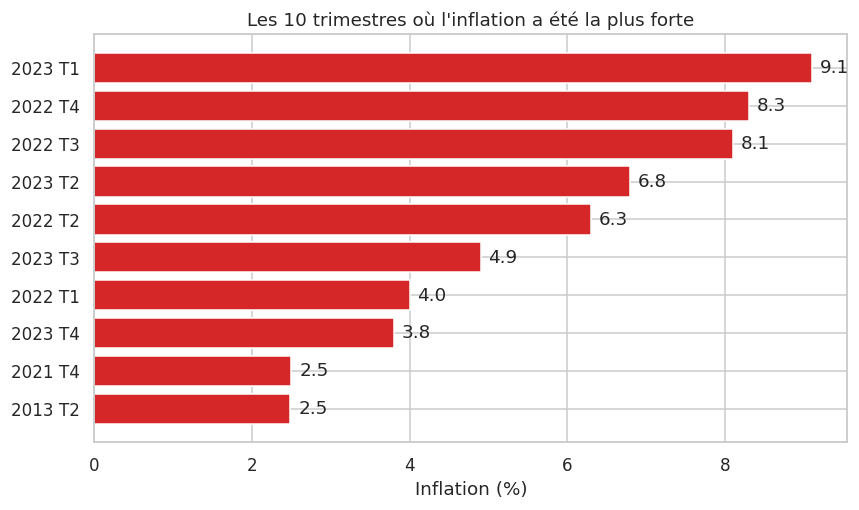

In [9]:
q5 = sql("""
SELECT periode, inflation
FROM inflation
ORDER BY inflation DESC
LIMIT 10;
""")
display(q5)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(q5["periode"], q5["inflation"], color="tab:red")
ax.invert_yaxis()
for i, v in enumerate(q5["inflation"]):
    ax.text(v + 0.1, i, f"{v:.1f}", va="center")
ax.set_xlabel("Inflation (%)")
ax.set_title("Les 10 trimestres où l'inflation a été la plus forte")
plt.tight_layout()
plt.show()

## 9. Requête 6 + graphique 4 : saisonnalité par trimestre

Y a-t-il un trimestre où l'inflation est en moyenne plus haute ? On regroupe par `trimestre` (T1 à T4).

,trimestre,inflation_moyenne,minimum,maximum
0,T1,1.84,-0.20,9.1
1,T2,1.88,0.00,6.8
2,T3,1.89,0.15,8.1
3,T4,1.78,-0.20,8.3


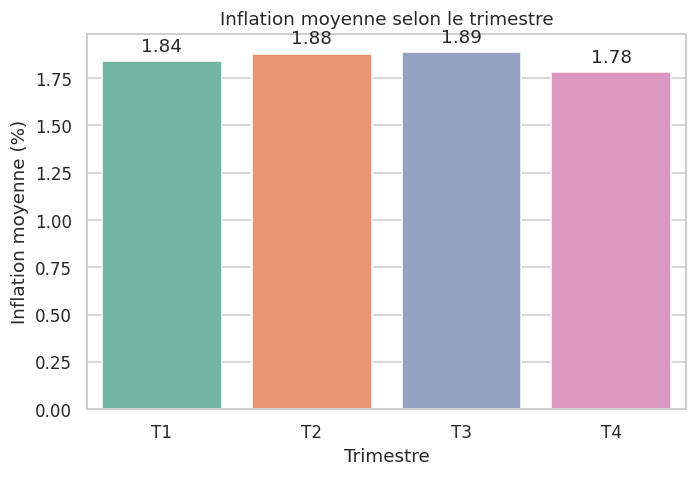

In [10]:
q6 = sql("""
SELECT trimestre,
       ROUND(AVG(inflation), 2) AS inflation_moyenne,
       ROUND(MIN(inflation), 2) AS minimum,
       ROUND(MAX(inflation), 2) AS maximum
FROM inflation
GROUP BY trimestre
ORDER BY trimestre;
""")
display(q6)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.barplot(data=q6, x="trimestre", y="inflation_moyenne", hue="trimestre", legend=False, ax=ax)
for i, v in enumerate(q6["inflation_moyenne"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")
ax.set_xlabel("Trimestre")
ax.set_ylabel("Inflation moyenne (%)")
ax.set_title("Inflation moyenne selon le trimestre")
plt.tight_layout()
plt.show()

## 10. Requête 7 + graphique 5 : comparaison par grande période

`CASE WHEN` crée des catégories directement en SQL : avant 2020, période Covid, pic d'inflation 2022-2023 et après.

,periode_eco,nb_trimestres,inflation_moyenne,maximum
0,1. 2013-2019 : avant Covid,28,1.17,2.49
1,2. 2020-2021 : Covid,8,1.01,2.50
2,3. 2022-2023 : pic d inflation,8,6.41,9.10
3,4. 2024-2026 : après le pic,10,0.77,2.00


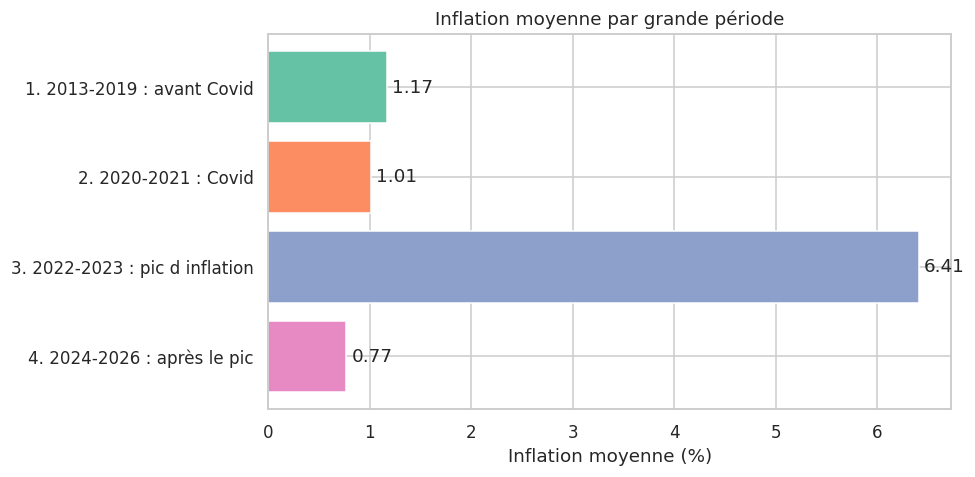

In [11]:
q7 = sql("""
SELECT CASE
         WHEN annee <= 2019 THEN '1. 2013-2019 : avant Covid'
         WHEN annee <= 2021 THEN '2. 2020-2021 : Covid'
         WHEN annee <= 2023 THEN '3. 2022-2023 : pic d inflation'
         ELSE                    '4. 2024-2026 : après le pic'
       END                        AS periode_eco,
       COUNT(*)                   AS nb_trimestres,
       ROUND(AVG(inflation), 2)   AS inflation_moyenne,
       ROUND(MAX(inflation), 2)   AS maximum
FROM inflation
GROUP BY periode_eco
ORDER BY periode_eco;
""")
display(q7)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(q7["periode_eco"], q7["inflation_moyenne"],
        color=sns.color_palette("Set2", len(q7)))
ax.invert_yaxis()
for i, v in enumerate(q7["inflation_moyenne"]):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center")
ax.set_xlabel("Inflation moyenne (%)")
ax.set_title("Inflation moyenne par grande période")
plt.tight_layout()
plt.show()

## 11. Requête 8 + graphique 6 : variation d'un trimestre à l'autre

La fonction de fenêtre `LAG()` va chercher la valeur du trimestre précédent, ce qui permet de calculer l'accélération ou le ralentissement de l'inflation.

,ordre,periode,inflation,variation
1,2,2013 T2,2.485969,0.18
2,3,2013 T3,1.736803,-0.75
3,4,2013 T4,0.981906,-0.75
4,5,2014 T1,0.444498,-0.54
5,6,2014 T2,0.030313,-0.41
6,7,2014 T3,0.147861,0.12
7,8,2014 T4,1.149642,1.00
8,9,2015 T1,1.500000,0.35
9,10,2015 T2,2.000000,0.50
10,11,2015 T3,1.900000,-0.10


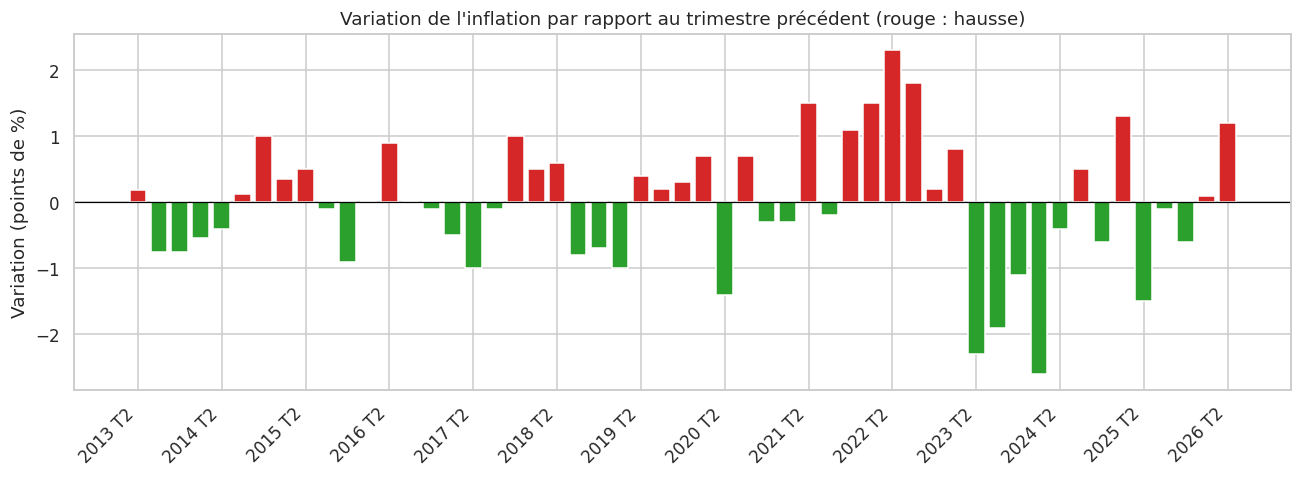

In [12]:
q8 = sql("""
SELECT ordre,
       periode,
       inflation,
       ROUND(inflation - LAG(inflation) OVER (ORDER BY ordre), 2) AS variation
FROM inflation
ORDER BY ordre;
""")
display(q8.dropna().head(10))

v = q8.dropna()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(v["ordre"], v["variation"],
       color=["tab:red" if x > 0 else "tab:green" for x in v["variation"]])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(v["ordre"][::4])
ax.set_xticklabels(v["periode"][::4], rotation=45, ha="right")
ax.set_ylabel("Variation (points de %)")
ax.set_title("Variation de l'inflation par rapport au trimestre précédent (rouge : hausse)")
plt.tight_layout()
plt.show()

## 12. Requête 9 : trimestres de déflation

Quels trimestres ont une inflation négative ? Cette requête n'a pas de graphique : le tableau suffit.

In [13]:
sql("""
SELECT periode, inflation
FROM inflation
WHERE inflation < 0
ORDER BY ordre;
""")

,periode,inflation
0,2019 T1,-0.2
1,2025 T4,-0.2
2,2026 T1,-0.1


## 13. Requête 10 : nombre de trimestres au-dessus de 2 % par année

,annee,trimestres_au_dessus_de_2
0,2013,2
1,2014,0
2,2015,0
3,2016,0
4,2017,0
5,2018,1
6,2019,0
7,2020,0
8,2021,1
9,2022,4


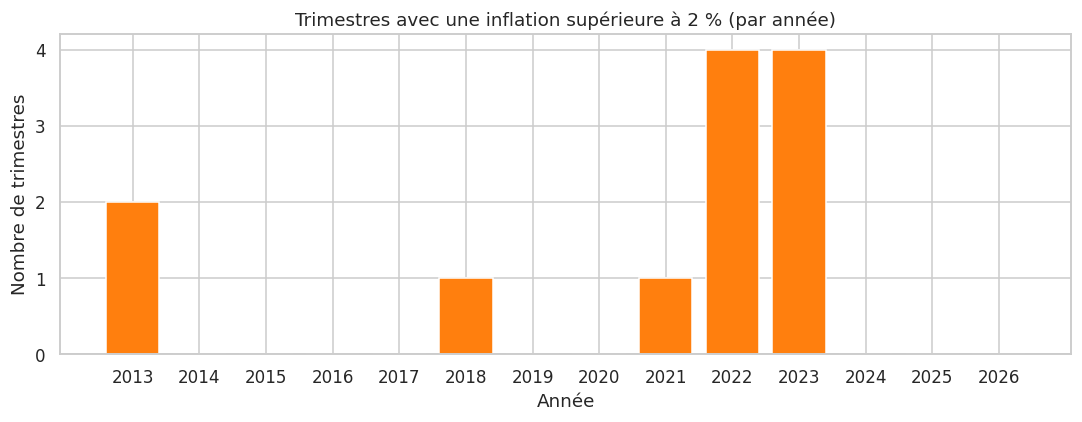

In [14]:
q10 = sql("""
SELECT annee,
       SUM(CASE WHEN inflation > 2 THEN 1 ELSE 0 END) AS trimestres_au_dessus_de_2
FROM inflation
GROUP BY annee
ORDER BY annee;
""")
display(q10)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(q10["annee"].astype(str), q10["trimestres_au_dessus_de_2"], color="tab:orange")
ax.set_yticks(range(0, 5))
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de trimestres")
ax.set_title("Trimestres avec une inflation supérieure à 2 % (par année)")
plt.tight_layout()
plt.show()

## 14. Fermeture de la connexion

In [15]:
conn.close()